# CALMQUEST: The Lost Light - Session Data Analysis

> **Data notice.** By default this notebook loads `data/sample_sessions_SYNTHETIC.csv`, which is
> **synthetic example data generated with a fixed random seed**. It is *not* player data, and every
> number and chart below only demonstrates that the pipeline works. To analyse real, consented
> sessions, export them from the game (*Data & Privacy -> Export CSV*) and set `DATA_PATH` below.

**Score convention (identical to the game):** `score_delta = post_stress_score - pre_stress_score`.
Negative = the post-session self-reported score was lower; positive = higher; zero = no numerical change.
Skipped answers stay missing and are never treated as `0` (0 is a valid answer).

All results are **descriptive**. Self-reported scores from an uncontrolled, small sample cannot show
that the game caused any change.

## 1. Imports and environment

In [1]:
import platform
import sys
from pathlib import Path

import matplotlib
import pandas as pd
from IPython.display import display

sys.path.insert(0, str(Path.cwd()))          # analysis/ when run from this folder
sys.path.insert(0, str(Path.cwd() / "analysis"))  # repository root
import analyze_sessions as an

print("Python    ", platform.python_version())
print("pandas    ", pd.__version__)
print("matplotlib", matplotlib.__version__)

Python     3.12.3
pandas     2.2.2
matplotlib 3.9.2


## 2. Data loading

In [2]:
repo_root = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_PATH = repo_root / "data" / "sample_sessions_SYNTHETIC.csv"   # <- point this to a real export
IS_SYNTHETIC = "SYNTHETIC" in DATA_PATH.name.upper()
LABEL = " (SYNTHETIC example data)" if IS_SYNTHETIC else ""

raw = an.load_raw(DATA_PATH)
print(f"Loaded {len(raw)} rows from {DATA_PATH.name}")
if IS_SYNTHETIC:
    print("SYNTHETIC example data: results below demonstrate the pipeline only.")
raw.head()

Loaded 65 rows from sample_sessions_SYNTHETIC.csv
SYNTHETIC example data: results below demonstrate the pipeline only.


,schema_version,session_id,session_started_at,pre_stress_score,recommended_mode,selected_mode,final_mode,session_duration_seconds,hints_used,interaction_help_events,items_collected,garden_restored,post_stress_score,score_delta,experience_rating,completed
0,1,cq-4f007746be9048db,2026-09-02T03:22:00,4,balanced,balanced,balanced,508,2,0,10,false,4,0,4,true
1,1,cq-713707c5b998a6cb,2026-09-02T15:36:00,8,gentle,gentle,gentle,60,2,0,13,true,7,-1,2,true
2,1,cq-85e3da60cf3a4aeb,2026-09-03T13:22:00,1,balanced,balanced,balanced,738,0,0,13,false,0,-1,5,true
3,1,cq-efb63ea816998060,2026-09-04T05:09:00,,,balanced,balanced,268,0,0,9,true,7,,5,true
4,1,cq-4cb4e482fcbfeaa5,2026-09-04T19:01:00,0,balanced,balanced,playful,487,1,0,1,false,,,,true


## 3. Schema validation

In [3]:
schema = an.validate_schema(raw)
schema

{'missing_columns': [],
 'unexpected_columns': [],
 'column_order_matches': True,
 'schema_versions': ['1']}

## 4. Missing-value inspection
Empty cells per column (before any conversion). Missing scores are expected when players skip a question.

In [4]:
(raw == "").sum().to_frame("empty_cells").T

,schema_version,session_id,session_started_at,pre_stress_score,recommended_mode,selected_mode,final_mode,session_duration_seconds,hints_used,interaction_help_events,items_collected,garden_restored,post_stress_score,score_delta,experience_rating,completed
empty_cells,0,0,0,12,13,0,0,0,0,0,0,0,14,18,20,0


## 5. Duplicate inspection

In [5]:
dupes = raw[raw["session_id"].duplicated(keep=False)]
print(f"Rows sharing a session_id: {len(dupes)}")
dupes[["session_id", "session_started_at", "pre_stress_score", "post_stress_score"]]

Rows sharing a session_id: 2


,session_id,session_started_at,pre_stress_score,post_stress_score
7,cq-99de1db70fe04a15,2026-09-05T19:47:00,0,
62,cq-99de1db70fe04a15,2026-09-05T19:47:00,0,


## 6. Data-type conversion
Text cells become nullable integers / booleans / timestamps. Non-numeric or fractional values become `<NA>` here and are reported as issues in the next step, so they are never silently used.

In [6]:
typed = an.coerce_types(raw)
typed.dtypes.to_frame("dtype").T

,schema_version,session_id,session_started_at,pre_stress_score,recommended_mode,selected_mode,final_mode,session_duration_seconds,hints_used,interaction_help_events,items_collected,garden_restored,post_stress_score,score_delta,experience_rating,completed
dtype,Int64,object,datetime64[ns],Int64,object,object,object,Int64,Int64,Int64,Int64,boolean,Int64,Int64,Int64,boolean


## 7. Score range and 8. duration validation
Every problem found in the file (scores outside 0-10, negative or implausible durations, inconsistent deltas, unknown modes, duplicates, non-numeric text):

In [7]:
report = an.find_issues(raw, typed)
report.issues

,row,session_id,column,value,problem
0,66,cq-badbadbadbad0004,hints_used,two,not a whole number
1,62,cq-badbadbadbad0001,pre_stress_score,12,score outside 0-10
2,63,cq-badbadbadbad0002,session_duration_seconds,-40,negative value
3,65,cq-badbadbadbad0003,score_delta,2,does not equal post - pre
4,64,cq-99de1db70fe04a15,session_id,cq-99de1db70fe04a15,duplicate session_id (later copy)


In [8]:
valid, excluded = an.split_valid(raw, typed, report)
print(f"Valid records: {len(valid)}   Excluded records: {len(excluded)} (excluded whole, never repaired)")

Valid records: 60   Excluded records: 5 (excluded whole, never repaired)


## 9. Basic descriptive statistics (valid records)

In [9]:
numeric_cols = ["pre_stress_score", "post_stress_score", "score_delta", "session_duration_seconds",
                "hints_used", "interaction_help_events", "items_collected", "experience_rating"]
valid[numeric_cols].astype("float").describe().round(2)

,pre_stress_score,post_stress_score,score_delta,session_duration_seconds,hints_used,interaction_help_events,items_collected,experience_rating
count,48.00,47.00,44.00,60.00,60.00,60.00,60.00,42.00
mean,4.08,3.96,-0.39,474.38,0.67,0.23,9.80,3.57
std,3.34,2.96,1.35,180.68,0.91,0.43,3.97,1.11
min,0.00,0.00,-4.00,60.00,0.00,0.00,1.00,2.00
25%,1.00,2.00,-1.00,393.00,0.00,0.00,8.00,3.00
50%,4.00,4.00,0.00,479.50,0.00,0.00,9.00,4.00
75%,6.25,6.00,0.00,606.25,1.00,0.00,13.00,4.75
max,10.00,10.00,3.00,849.00,3.00,1.00,18.00,5.00


## 10. Distribution of pre-game scores

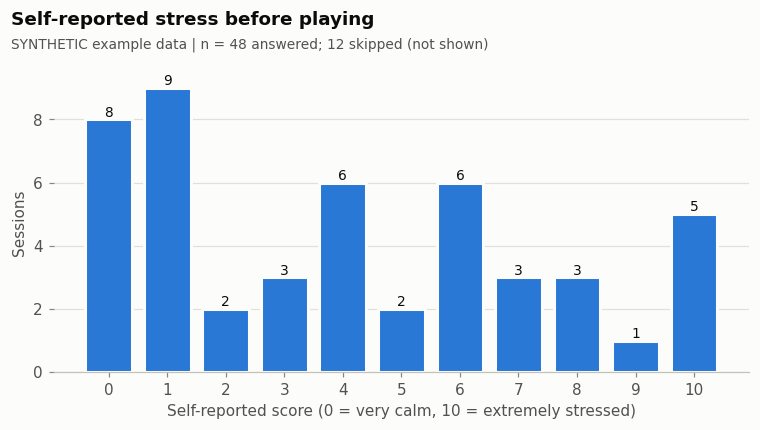

In [10]:
fig = an.chart_score_distribution(valid, "pre_stress_score", "Self-reported stress before playing", LABEL)

## 11. Distribution of post-game scores

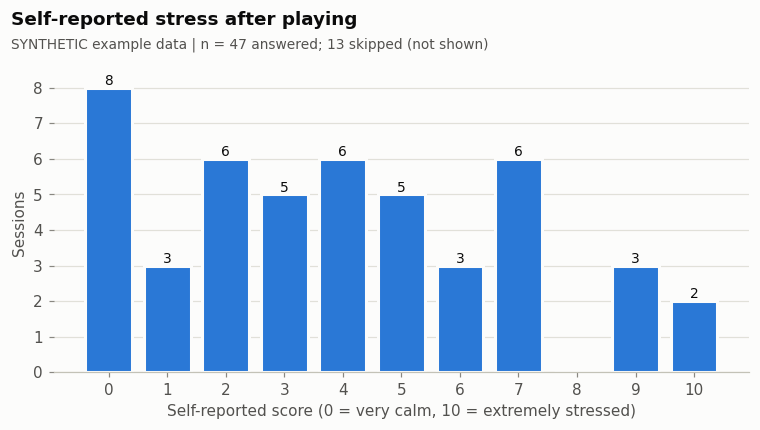

In [11]:
fig = an.chart_score_distribution(valid, "post_stress_score", "Self-reported stress after playing", LABEL)

## 12. Pre- and post-score comparison
Only sessions with **both** answers are compared; the number excluded for missing answers is reported.

Paired sessions: 44   Excluded from paired analysis (a score missing): 16


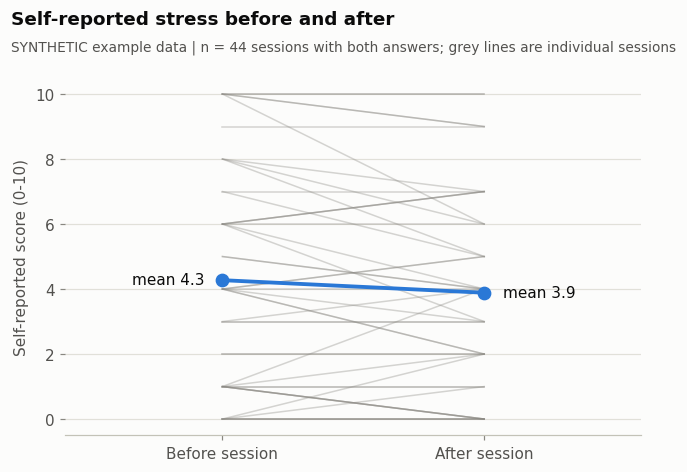

In [12]:
pairs, n_unpaired = an.paired_scores(valid)
print(f"Paired sessions: {len(pairs)}   Excluded from paired analysis (a score missing): {n_unpaired}")
fig = an.chart_pre_post(pairs, LABEL)

## 13. Score-change calculation
`score_delta` is recomputed here as `post - pre` for every pair (and the stored value was already checked for consistency).

{'delta_mean': -0.39, 'delta_median': 0.0, 'delta_negative': 18, 'delta_zero': 16, 'delta_positive': 10}


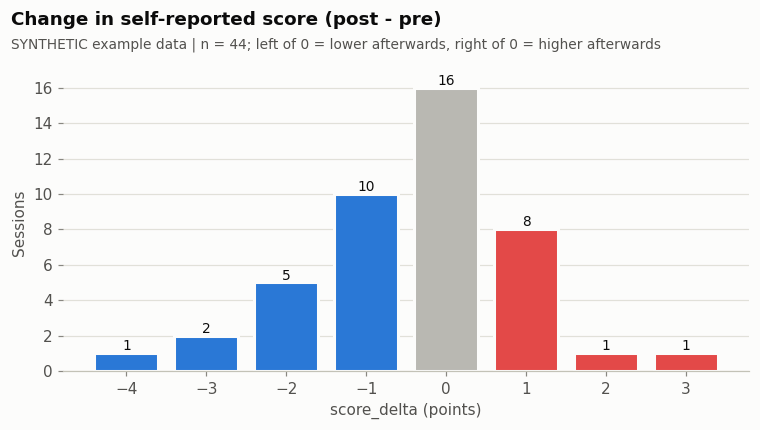

In [13]:
summary = an.summarize(valid)
print({k: summary[k] for k in ["delta_mean", "delta_median", "delta_negative", "delta_zero", "delta_positive"]})
fig = an.chart_delta_distribution(pairs, LABEL)

In [14]:
print(an.describe_change(summary))

In this dataset (n = 44 paired sessions), the average post-session self-reported score (3.89) was lower than the average pre-session score (4.27). This is a descriptive observation about self-reports; it does not show that the game caused any change.


## 14. Session duration analysis

count    60.0
mean      7.9
std       3.0
min       1.0
25%       6.6
50%       8.0
75%      10.1
max      14.2


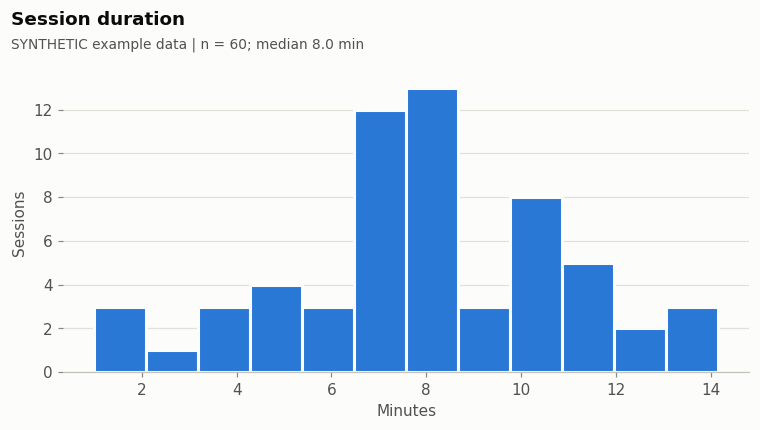

In [15]:
minutes = valid["session_duration_seconds"].astype(float) / 60
print(minutes.describe().round(1).to_string())
fig = an.chart_duration(valid, LABEL)

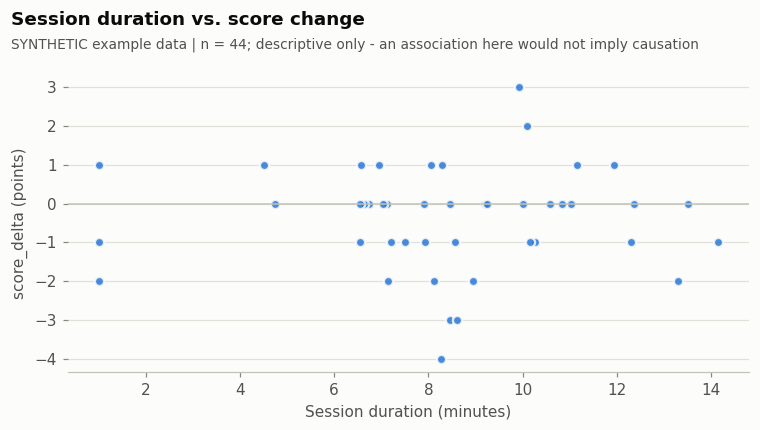

In [16]:
fig = an.chart_duration_vs_delta(pairs, LABEL)

The scatter above is shown with caution: with a small, self-selected sample any pattern may be noise, and even a clear association would not mean that longer sessions *cause* different scores.

## 15. Mode distribution

final_mode,balanced,gentle,playful,total
selected_mode,,,,
balanced,34,4,2,40
gentle,0,15,1,16
playful,0,0,4,4
total,34,19,7,60


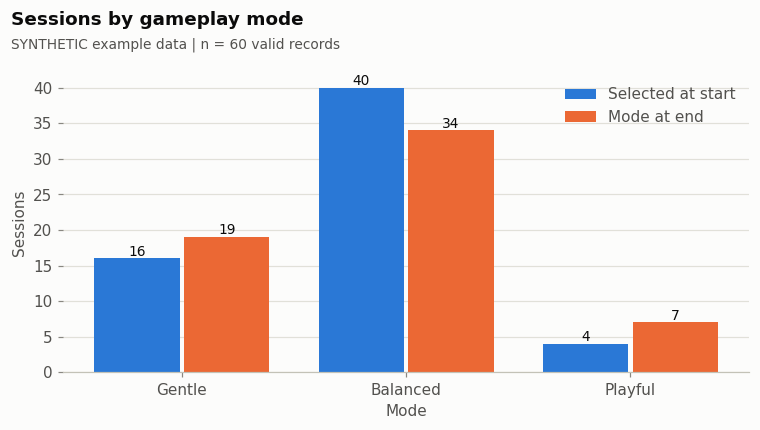

In [17]:
display(pd.crosstab(valid["selected_mode"], valid["final_mode"], margins=True, margins_name="total"))
fig = an.chart_modes(valid, LABEL)

## 16. Item collection analysis

,count,mean,std,min,25%,50%,75%,max
garden_restored,,,,,,,,
False,20.0,6.6,4.0,1.0,3.8,6.0,9.2,14.0
True,40.0,11.4,2.9,8.0,9.0,11.0,13.0,18.0


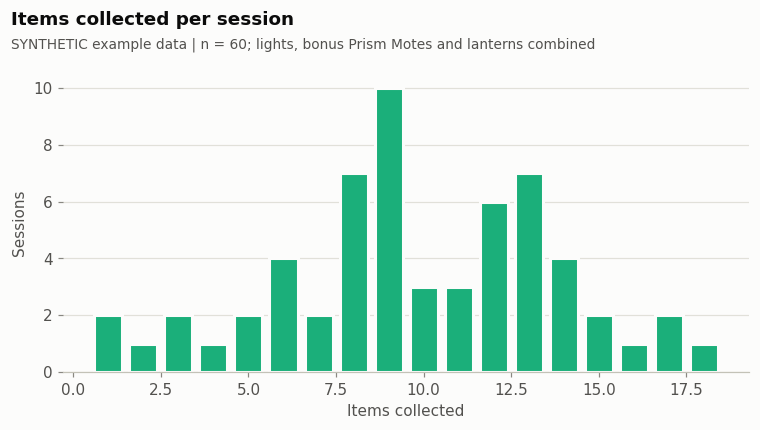

In [18]:
display(valid.groupby("garden_restored")["items_collected"].describe().round(1))
fig = an.chart_items(valid, LABEL)

## 17. Missing post-assessment analysis

,sessions
both answered,44
pre only (after skipped),4
post only (before skipped),3
neither answered,9


post score missing,False,True
completed,,
False,0,2
True,47,11


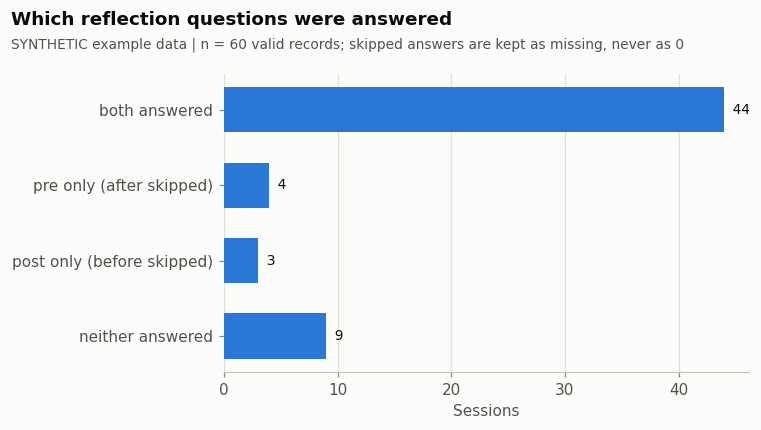

In [19]:
display(pd.Series(an.missingness(valid), name="sessions").to_frame())
skip_by_completion = pd.crosstab(valid["completed"], valid["post_stress_score"].isna(), rownames=["completed"], colnames=["post score missing"])
display(skip_by_completion)
fig = an.chart_missingness(valid, LABEL)

## 18. Interpretation and limitations

* **Synthetic data.** With the default file, every number above is invented and says nothing about real players.
* **Descriptive only.** Even with real data, a lower average post-session score does not show the game caused it.
  There is no control group, no randomisation, and many other things (time of day, rest, expectations,
  regression to the mean, the act of answering twice) can change a self-report.
* **Self-report, not measurement.** The 0-10 question is a subjective reflection, not a validated clinical
  instrument, and nothing here diagnoses or detects stress or anxiety.
* **Missing data are informative.** Players who skip the after-play question may differ from those who answer;
  paired results only describe players who answered both.
* **Small, self-selected samples.** Consented local records come from whoever chose to opt in.
* **Next step.** A causal question would need a pre-registered study design (e.g. comparison with a
  control activity), an adequate sample size, ethics review and validated measures - see `docs/EVALUATION_PLAN.md`.